In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

# 🛑 DATA VISUALIZATION

In [66]:
df = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataCleaned.csv', index_col='ID')
df.head()

,age,sex,dzgroup,dzclass,num.co,edu,income,charges,totcst,avtisst,...,crea,sod,ph,bun,urine,adlsc,death,hospdead,sfdm2,Adls_Adlp_merge
ID,,,,,,,,,,,,,,,,,,,,,
0,62.84998,male,Lung Cancer,Cancer,0,11.000000,$11-$25k,9715.0,31100.865401,7.000000,...,1.199951,141.0,7.459961,6.51,2502.0,7.0,0,0,0,7.0
1,60.33899,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.000000,$11-$25k,34496.0,31100.865401,29.000000,...,5.500000,132.0,7.250000,6.51,2502.0,1.0,1,1,<2 mo. follow-up,1.0
2,52.74698,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.000000,under $11k,41094.0,31100.865401,13.000000,...,2.000000,134.0,7.459961,6.51,2502.0,0.0,1,0,<2 mo. follow-up,0.5
3,42.38498,female,Lung Cancer,Cancer,2,11.000000,under $11k,3075.0,31100.865401,7.000000,...,0.799927,139.0,7.415340,6.51,2502.0,0.0,1,0,no(M2 and SIP pres),0.0
4,79.88495,female,ARF/MOSF w/Sepsis,ARF/MOSF,1,11.749662,Unknown,50127.0,31100.865401,18.666656,...,0.799927,143.0,7.509766,6.51,2502.0,2.0,0,0,no(M2 and SIP pres),2.0


<Axes: ylabel='count'>

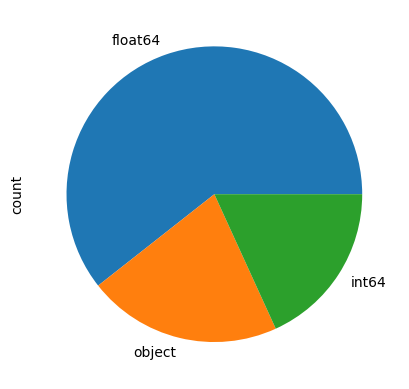

In [67]:
df.dtypes.value_counts().plot.pie()

In [68]:
df.dtypes.value_counts()

float64    20
object      7
int64       6
Name: count, dtype: int64

In [69]:
numercial_features = df.select_dtypes(include=['int64', 'float64'])
numercial_features=numercial_features .drop(['death', 'hospdead', 'diabetes', 'dementia'], axis=1)

categorical_features = df.select_dtypes(include=['object'])
categorical_features = pd.concat([categorical_features, df[['death', 'hospdead', 'diabetes', 'dementia']]], axis=1)

### DISTRIBUTION ANALYSIS

### BOX PLOT - QUANTITATIVE DATA

The artificial vision diagnostic system extracts ten different features from the boundaries of the cell nuclei generated by the snake. All features are modeled numerically so that higher values ​​will typically indicate a higher probability of malignancy.

Street, W.N., Wolberg, W.H., & Mangasarian, O.L. (1993). Nuclear feature extraction for breast tumor diagnosis. Electronic imaging.

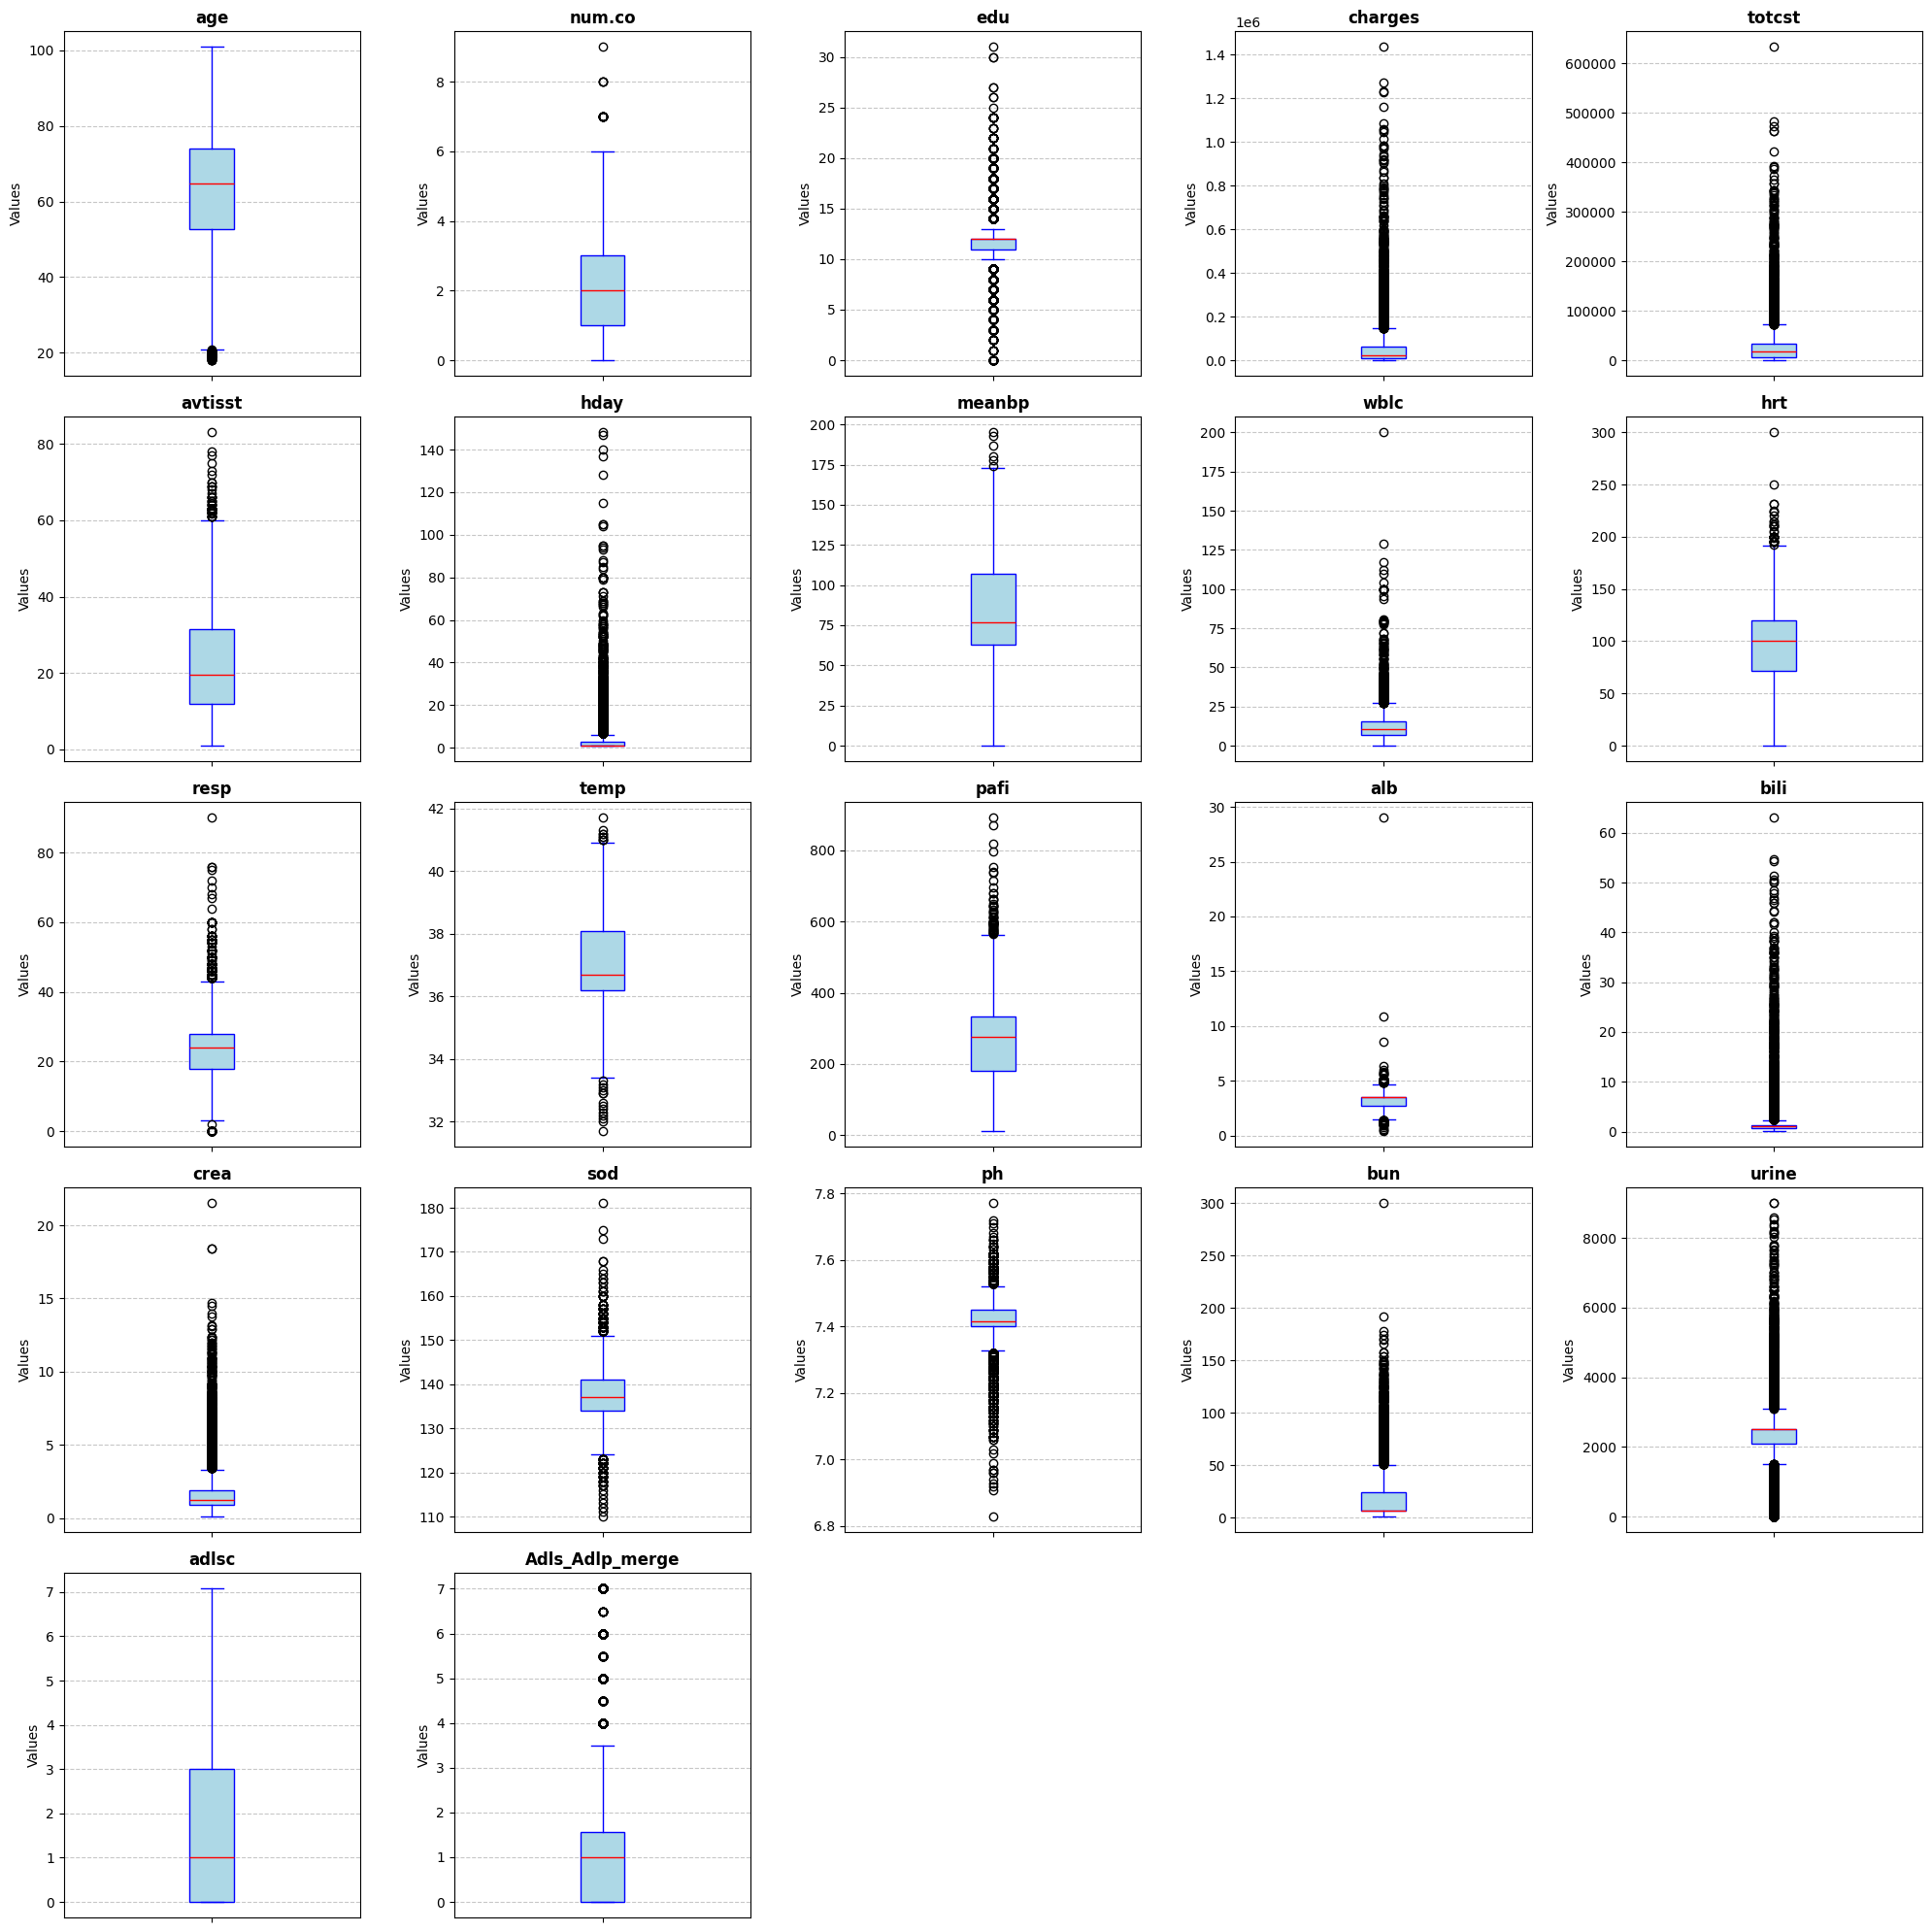

In [70]:
# Crear una cuadrícula de 5x5 figuras (25 en total)
fig, axes = plt.subplots(5, 5, figsize=(20, 20))
axes = axes.flatten()  # Convertir la cuadrícula en una lista unidimensional

# Iterar sobre las columnas de tu DataFrame "features" y crear los gráficos
for i, column in enumerate(numercial_features):
    # Crear un boxplot para la columna actual
    axes[i].boxplot(df[column], patch_artist=True,
                    boxprops=dict(facecolor='lightblue', color='blue'),
                    medianprops=dict(color='red'),
                    whiskerprops=dict(color='blue'),
                    capprops=dict(color='blue'))

    # Establecer título y etiquetas
    axes[i].set_title(column, fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Values', fontsize=10)

    # Agregar líneas de cuadrícula
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

    # Eliminar etiquetas del eje x para claridad
    axes[i].set_xticklabels([])

# Eliminar los 4 ejes sobrantes
for j in range(22, 25):
    fig.delaxes(axes[j])

# Ajustar el diseño para evitar superposición
plt.tight_layout()
plt.show()


### HISTOGRAMS - QUANTITATIVE DATA

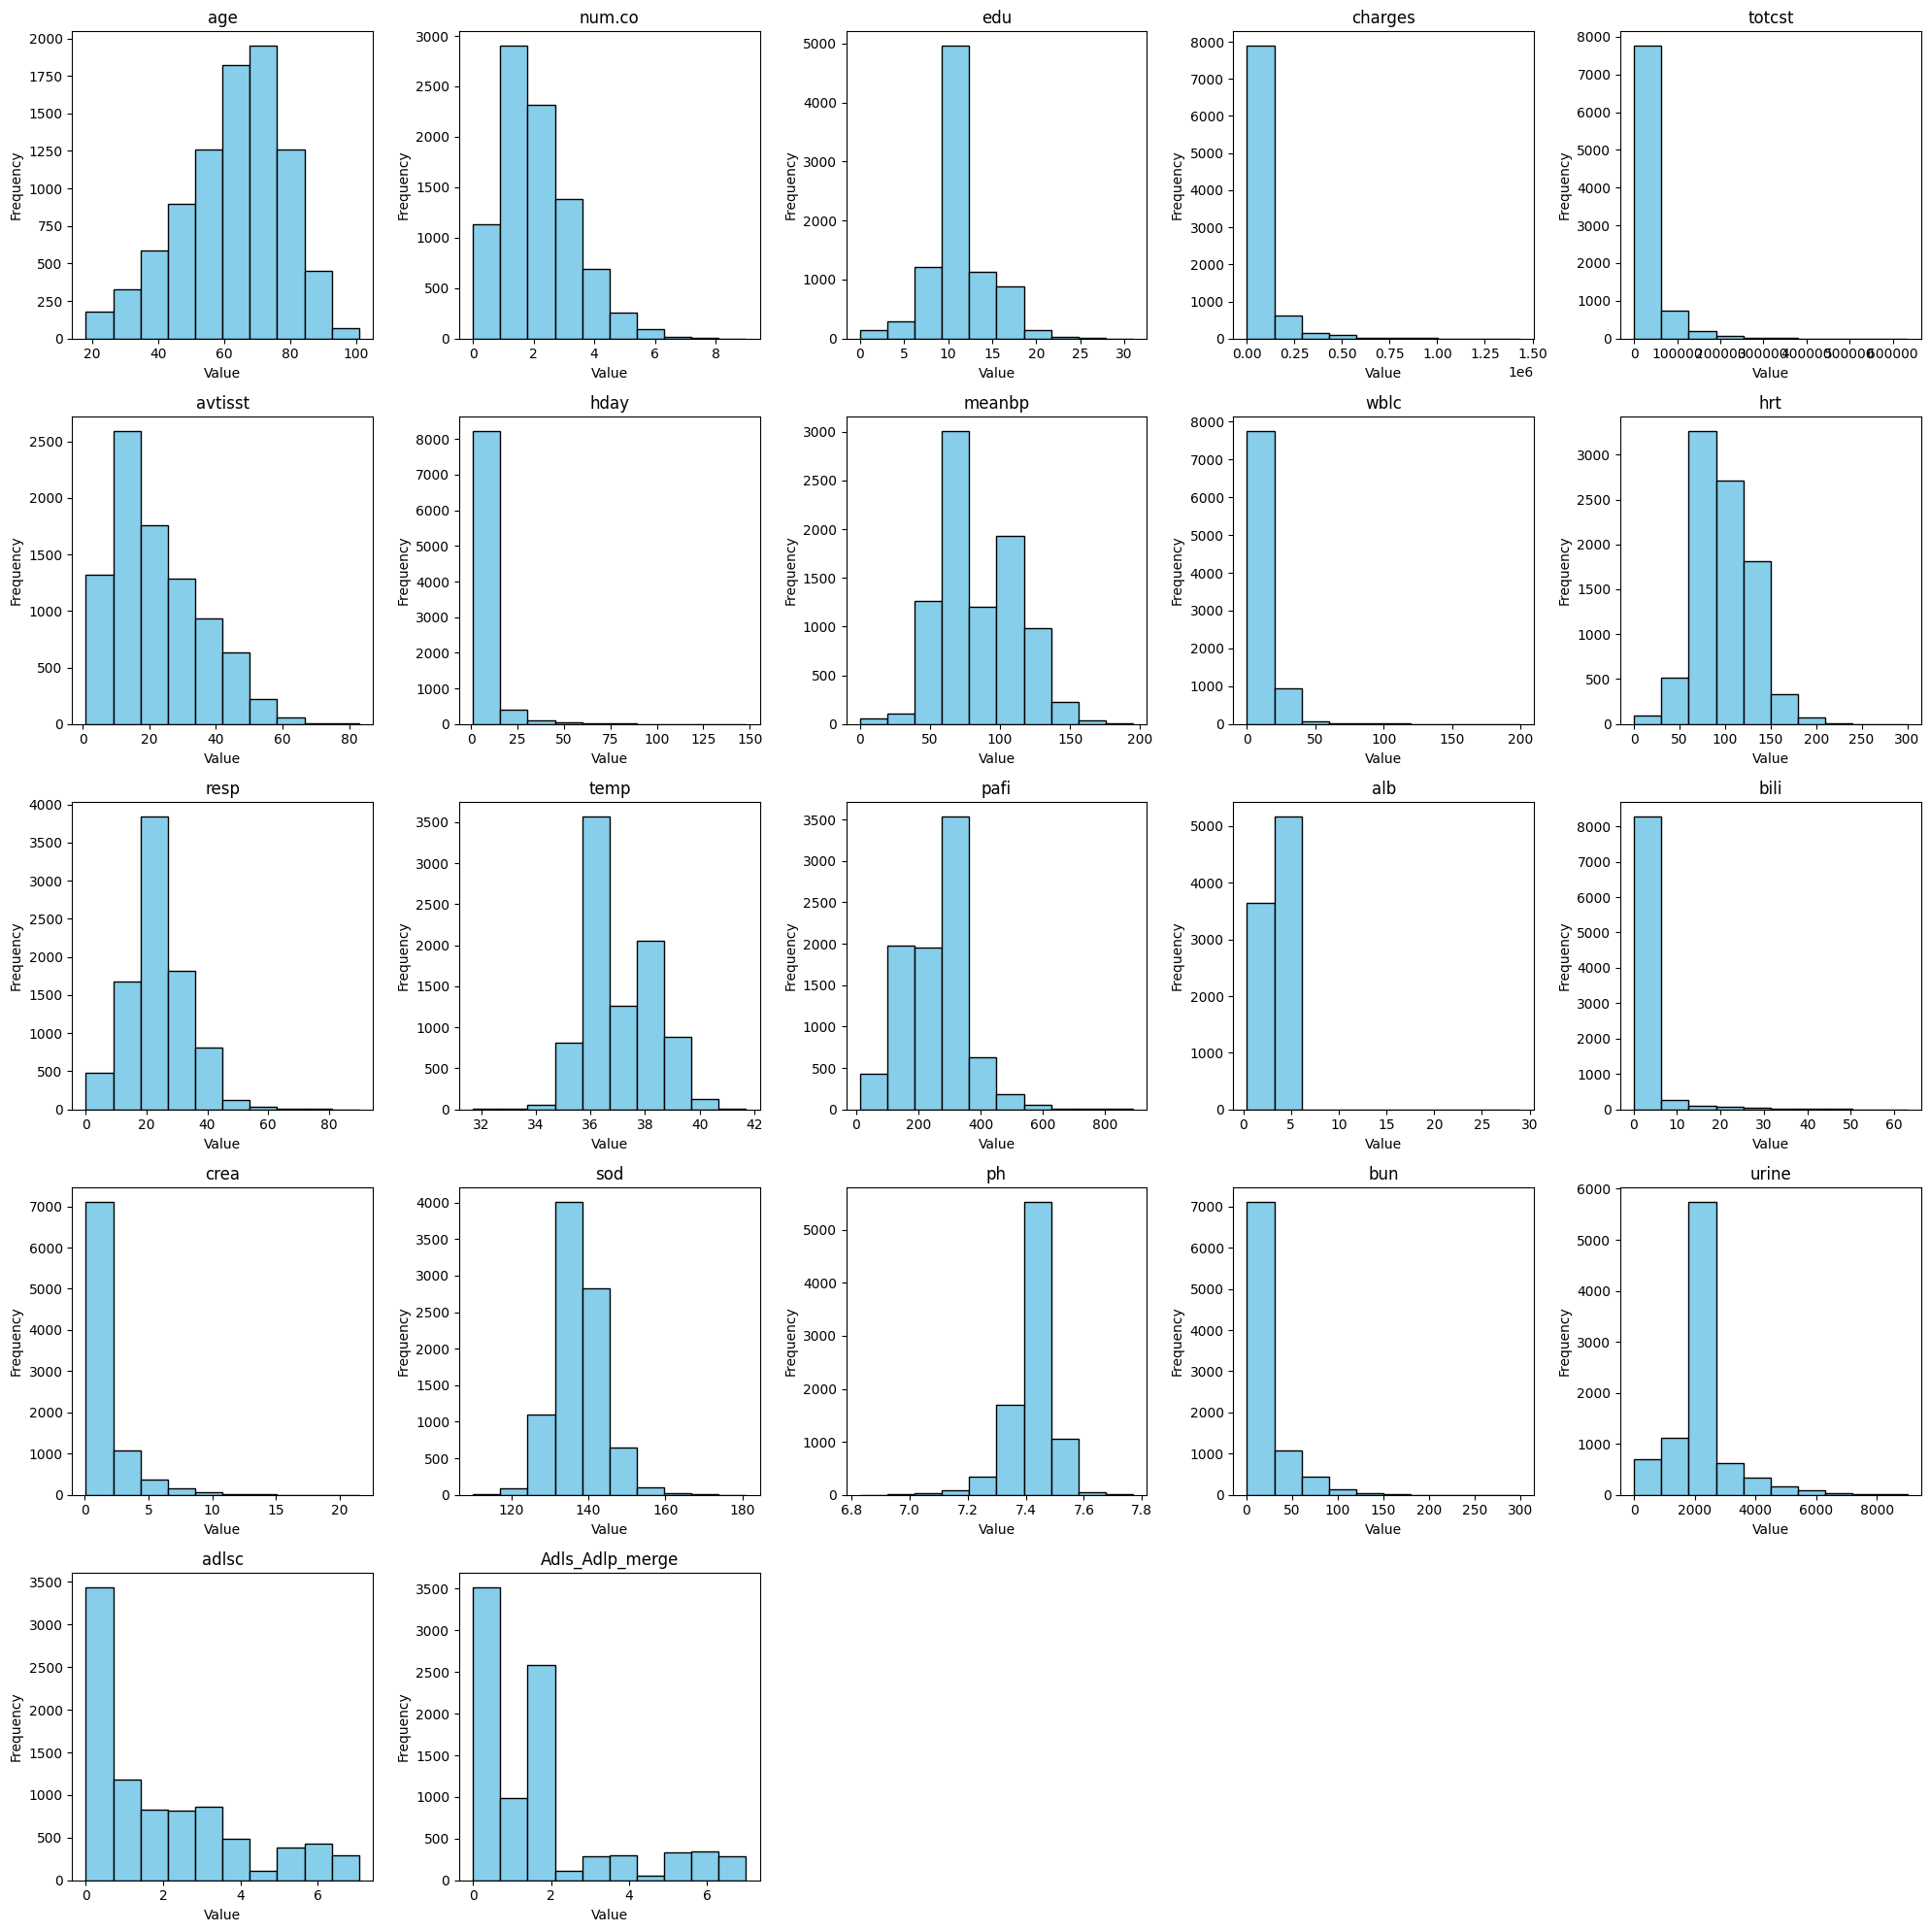

In [71]:
fig, axes = plt.subplots(5, 5, figsize=(20, 20))


axes = axes.flatten()

for i, column in enumerate(numercial_features):
    axes[i].hist(df[column], color='skyblue', edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Eliminar los 4 ejes sobrantes
for j in range(22, 25):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### BAR PLOTS - QUALITATIVE DATA

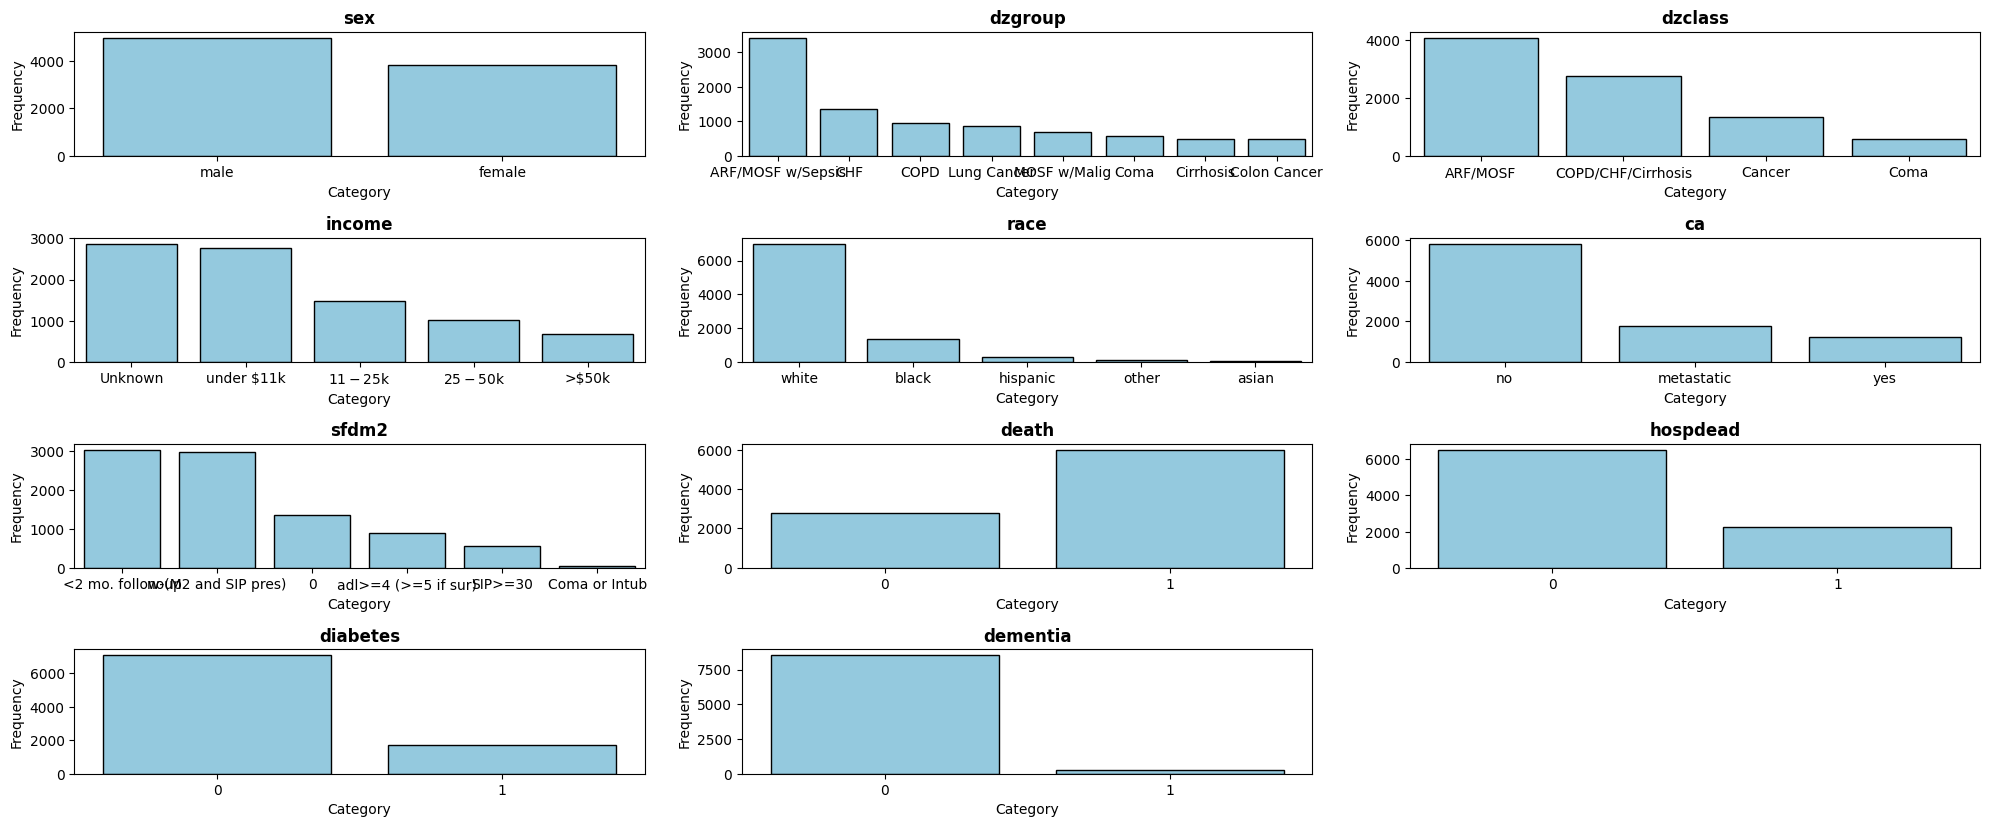

In [72]:
# Crear una cuadrícula de 3x5 figuras (15 en total)
fig, axes = plt.subplots(5, 3, figsize=(20, 10))
axes = axes.flatten()  # Convertir la cuadrícula en una lista unidimensional

# Iterar sobre las columnas de categorías y crear gráficos de barras
for i, column in enumerate(categorical_features):
    # Calcular el conteo de cada categoría
    category_counts = df[column].value_counts()

    # Crear un barplot con los conteos de categorías
    sns.barplot(x=category_counts.index, y=category_counts.values, ax=axes[i], color='skyblue', edgecolor='black')

    # Establecer título y etiquetas
    axes[i].set_title(column, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Category', fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=10)

# Eliminar los ejes sobrantes si hay menos de 15 columnas
for j in range(i + 1, 15):
    fig.delaxes(axes[j])

# Ajustar el diseño para evitar superposición
plt.tight_layout()
plt.show()

In [73]:
def create_pie_chart(column):
    # Calcular el conteo de cada categoría
    category_counts = column.value_counts()

    # Crear el gráfico de pastel (pie chart)
    plt.figure(figsize=(8, 8))
    plt.pie(category_counts.values, labels=category_counts.index, autopct='%1.1f%%',
            startangle=90, colors=plt.cm.Paired.colors, wedgeprops={'edgecolor': 'black', 'linewidth': 1.2})

    # Establecer título con estilo
    plt.title(f'Distribution of {column.name}', fontsize=14, fontweight='bold')

    # Mostrar el gráfico
    plt.axis('equal')  # Asegura que el gráfico sea circular
    plt.show()


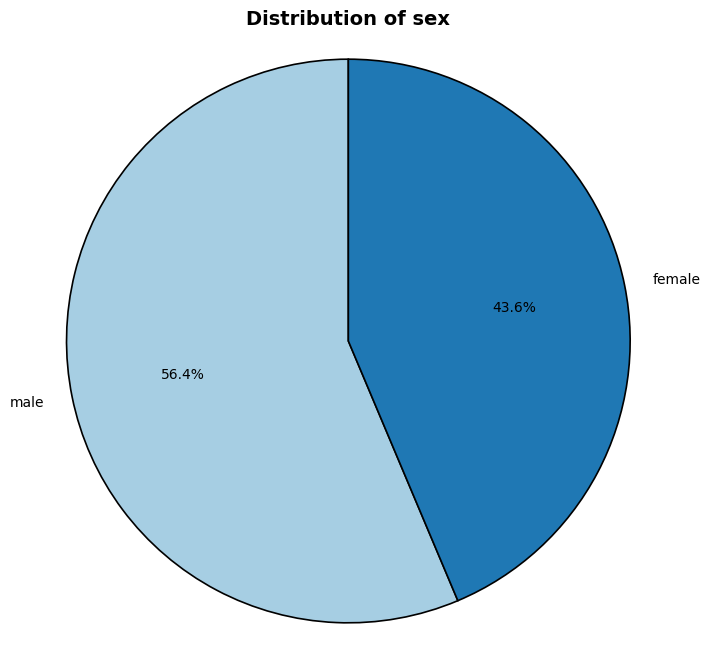

In [74]:
create_pie_chart(categorical_features['sex'])

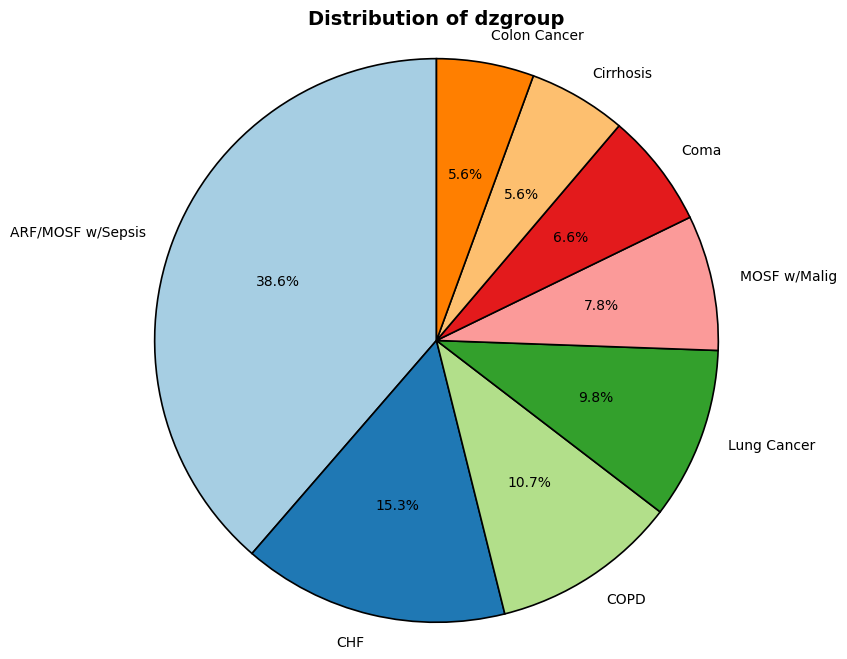

In [75]:
create_pie_chart(categorical_features['dzgroup'])

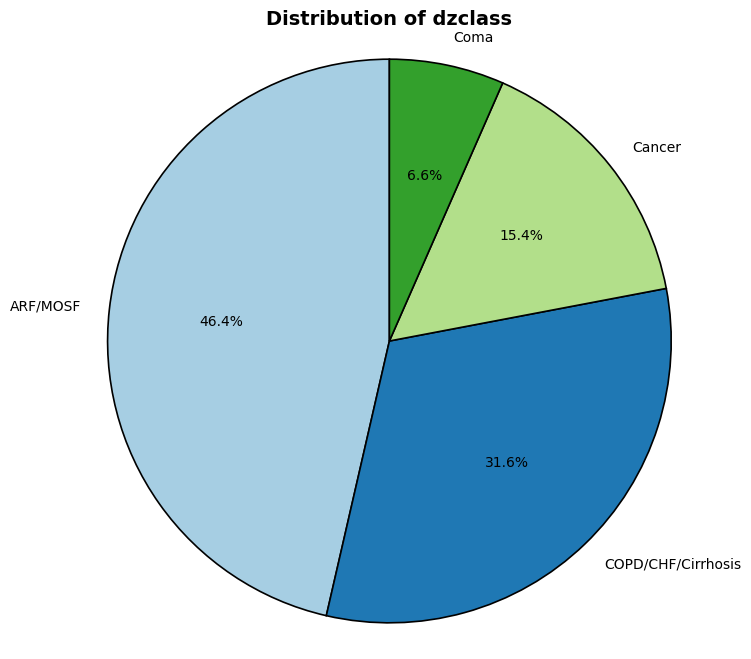

In [76]:
create_pie_chart(categorical_features['dzclass'])

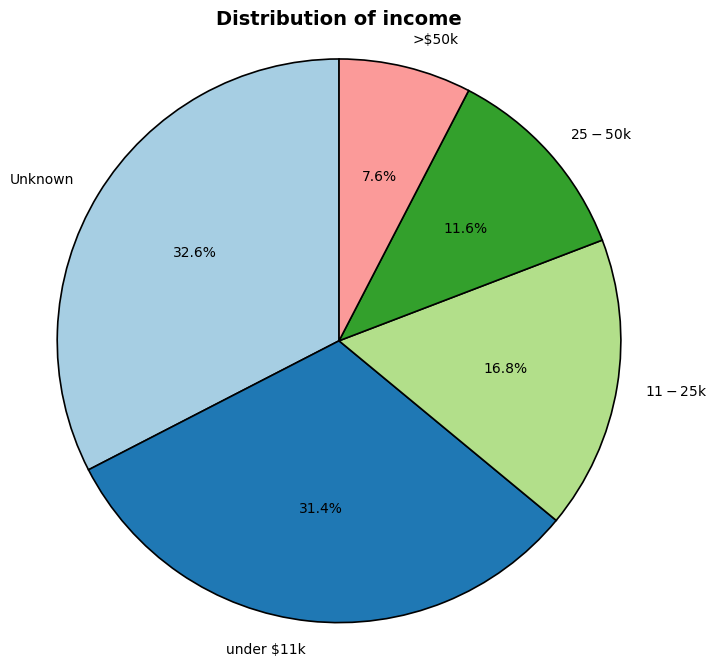

In [77]:
create_pie_chart(categorical_features['income'])

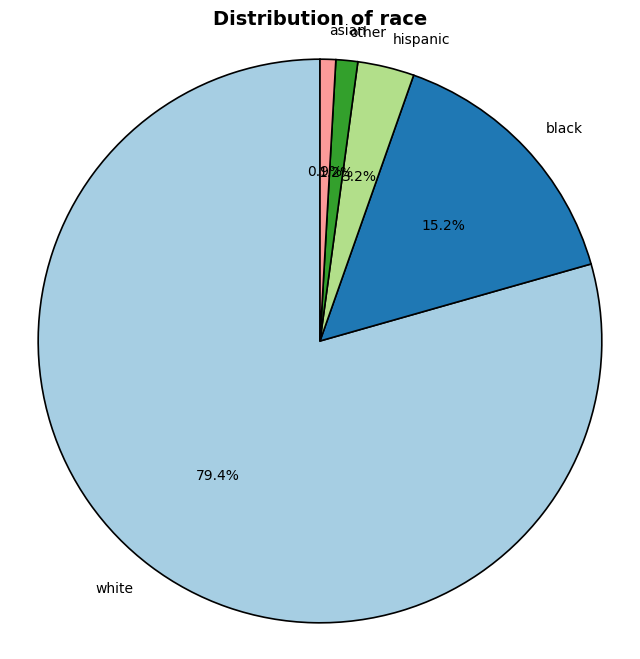

In [78]:
create_pie_chart(categorical_features['race'])

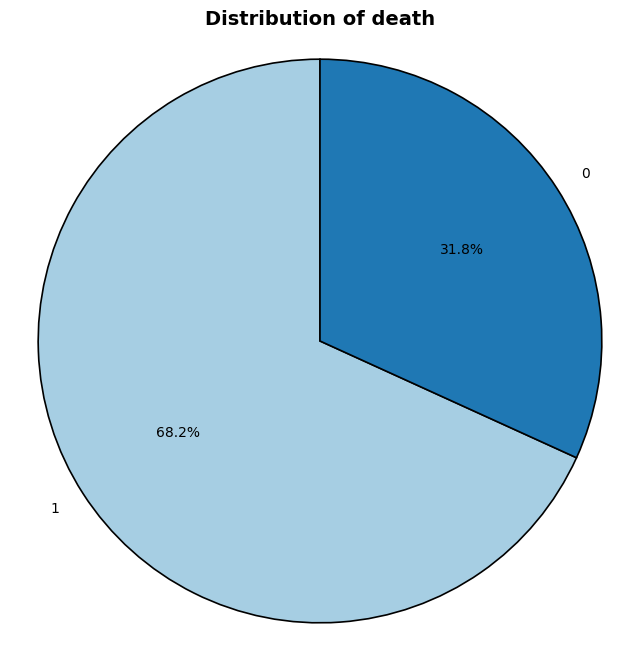

In [79]:
create_pie_chart(categorical_features['death'])

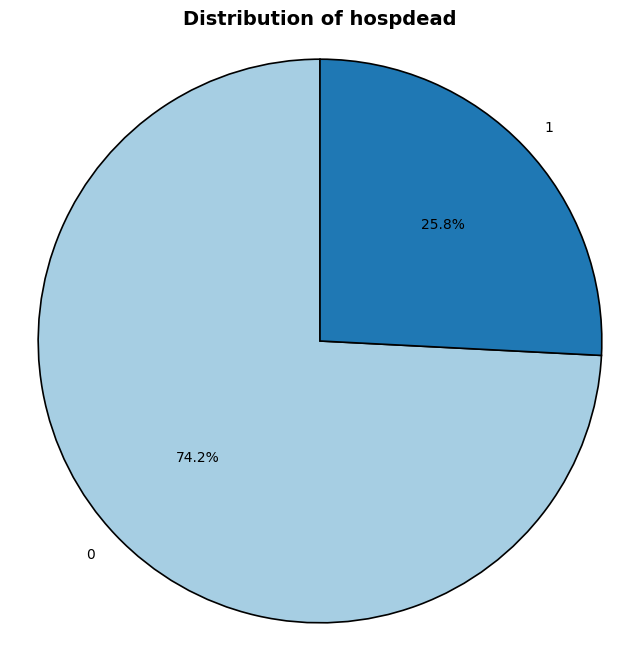

In [80]:
create_pie_chart(categorical_features['hospdead'])

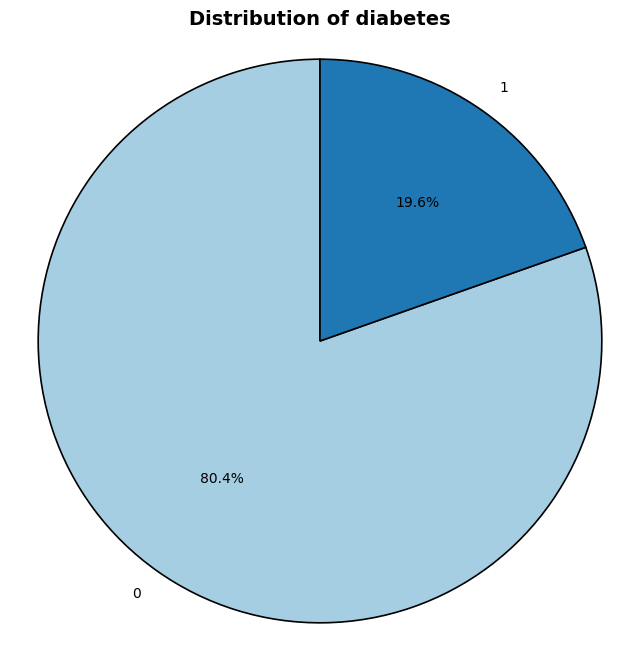

In [81]:
create_pie_chart(categorical_features['diabetes'])

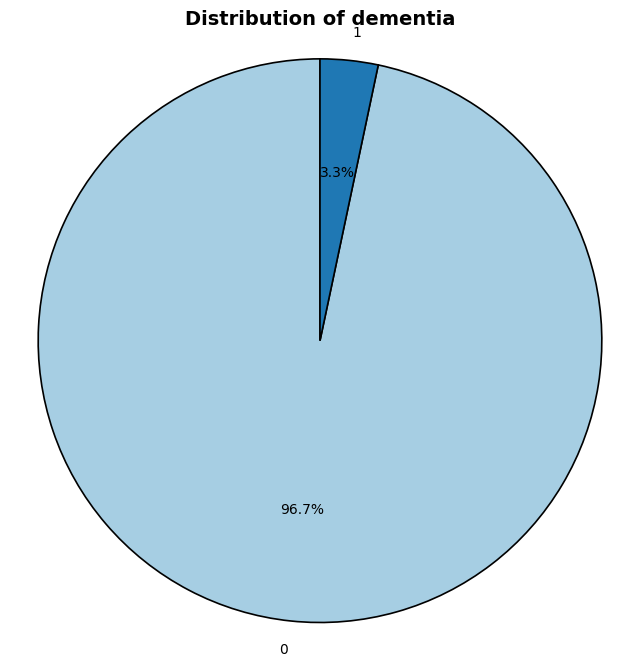

In [82]:
create_pie_chart(categorical_features['dementia'])

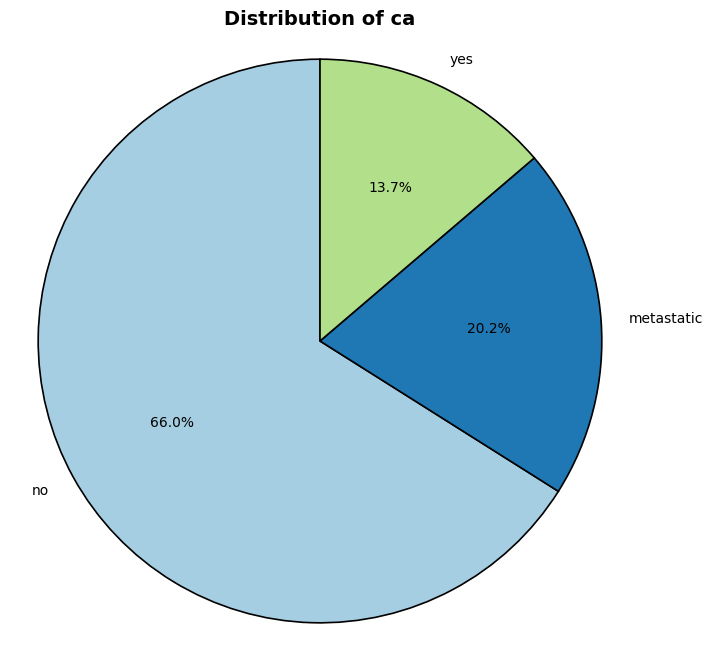

In [83]:
create_pie_chart(categorical_features['ca'])

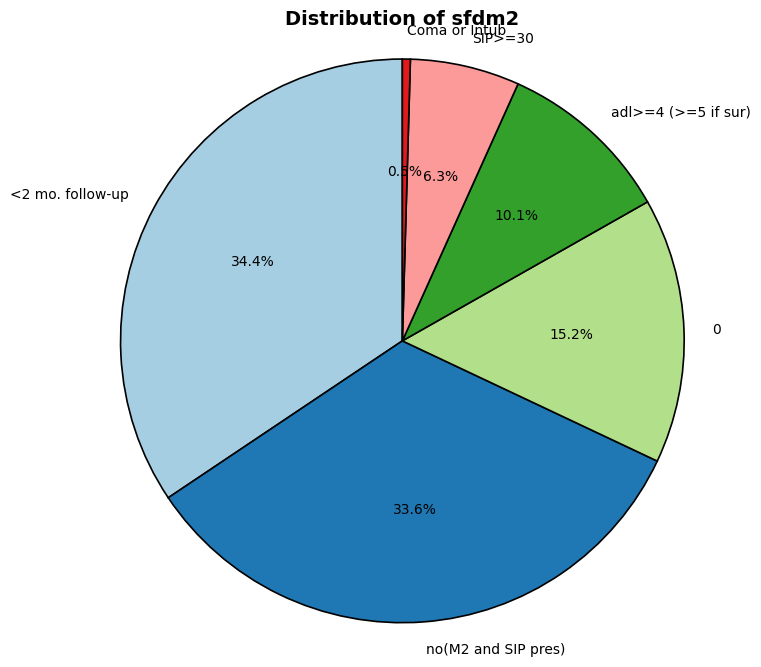

In [84]:
create_pie_chart(categorical_features['sfdm2'])

### 🛑 DATA TRANSFORMATION: MODIFICATION OF GROUPS TO BE NUMERIC

- SEX

In [85]:
categorical_features['sex'] = categorical_features['sex'].replace({'male': 0, 'female': 1})

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_43990/4193176824.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  categorical_features['sex'] = categorical_features['sex'].replace({'male': 0, 'female': 1})


- DZGROUP

In [86]:
categorical_features['dzgroup']=categorical_features['dzgroup'].replace({'ARF/MOSF w/Sepsis':1,'CHF':2,'COPD':3,'Lung Cancer':4,'MOSF w/Malig':5,'Coma':6,'Cirrhosis':7,'Colon Cancer':8})

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_43990/2186685541.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  categorical_features['dzgroup']=categorical_features['dzgroup'].replace({'ARF/MOSF w/Sepsis':1,'CHF':2,'COPD':3,'Lung Cancer':4,'MOSF w/Malig':5,'Coma':6,'Cirrhosis':7,'Colon Cancer':8})


- DZCLASS

In [87]:
categorical_features.loc[categorical_features['dzgroup'].isin([4, 8]), 'dzclass'] = 1
categorical_features.loc[categorical_features['dzgroup'].isin([6]), 'dzclass'] = 2
categorical_features.loc[categorical_features['dzgroup'].isin([3,2,7]), 'dzclass'] = 3
categorical_features.loc[categorical_features['dzgroup'].isin([1,5]), 'dzclass'] = 4

categorical_features['dzclass'] = categorical_features['dzclass'].astype(int)

- CA

In [88]:
categorical_features['ca'] = categorical_features['ca'].replace({'no': 0, 'yes': 1,'metastatic':2})

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_43990/1603412541.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  categorical_features['ca'] = categorical_features['ca'].replace({'no': 0, 'yes': 1,'metastatic':2})


- RACE

In [89]:
categorical_features['race'] = categorical_features['race'].replace({'other': 0, 'white': 1,'hispanic':2,'asian':3,'black':4})

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_43990/1735058258.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  categorical_features['race'] = categorical_features['race'].replace({'other': 0, 'white': 1,'hispanic':2,'asian':3,'black':4})


- INCOME

In [90]:
categorical_features['income']=categorical_features['income'].replace({'Unknown':0,'under $11k':1,'$11-$25k':2,'$25-$50k':3,'>$50k':4})

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_43990/3860242343.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  categorical_features['income']=categorical_features['income'].replace({'Unknown':0,'under $11k':1,'$11-$25k':2,'$25-$50k':3,'>$50k':4})


- sfdm2

In [91]:
categorical_features['sfdm2'].unique()

array(['0', '<2 mo. follow-up', 'no(M2 and SIP pres)', 'SIP>=30',
       'adl>=4 (>=5 if sur)', 'Coma or Intub'], dtype=object)

In [92]:
categorical_features['sfdm2']=categorical_features['sfdm2'].replace({'no(M2 and SIP pres)':1,'SIP>=30':3,'adl>=4 (>=5 if sur)':2,'Coma or Intub':4,'<2 mo. follow-up':5})

In [93]:
categorical_features.head()

,sex,dzgroup,dzclass,income,race,ca,sfdm2,death,hospdead,diabetes,dementia
ID,,,,,,,,,,,
0,0,4,1,2,0,2,0,0,0,0,0
1,1,7,3,2,1,0,5,1,1,0,0
2,1,7,3,1,1,0,5,1,0,0,0
3,1,4,1,1,1,2,1,1,0,0,0
4,1,1,4,0,1,0,1,0,0,0,0


In [94]:
df=pd.concat([numercial_features,categorical_features],axis=1)

In [95]:
df.head()

,age,num.co,edu,charges,totcst,avtisst,hday,meanbp,wblc,hrt,...,dzgroup,dzclass,income,race,ca,sfdm2,death,hospdead,diabetes,dementia
ID,,,,,,,,,,,,,,,,,,,,,
0,62.84998,0,11.000000,9715.0,31100.865401,7.000000,1,97.0,6.000000,69.0,...,4,1,2,0,2,0,0,0,0,0
1,60.33899,2,12.000000,34496.0,31100.865401,29.000000,3,43.0,17.097656,112.0,...,7,3,2,1,0,5,1,1,0,0
2,52.74698,2,12.000000,41094.0,31100.865401,13.000000,4,70.0,8.500000,88.0,...,7,3,1,1,0,5,1,0,0,0
3,42.38498,2,11.000000,3075.0,31100.865401,7.000000,1,75.0,9.099609,88.0,...,4,1,1,1,2,1,1,0,0,0
4,79.88495,1,11.749662,50127.0,31100.865401,18.666656,3,59.0,13.500000,112.0,...,1,4,0,1,0,1,0,0,0,0


In [96]:
df.to_csv("/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels.csv")
numercial_features.to_csv("/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv")
categorical_features.to_csv("/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv")
